# M01 · Outage-scan skeleton (v0.1, three tiers, illustrative)
**Project:** Energy Resilience Under Prolonged Grid Outages: Which Source Holds When the Grid Doesn't? (case study: ATÜ campus, Adana)
**Date:** 6 Nov 2026 · **Author:** Ahmet Selahaddin Topbaş (TOPBASCH Systems Lab)

**What this notebook is.** A working skeleton of the method: an hourly energy balance in which a grid outage is started at *every hour of the year*, for four source options, and the result is read as a function of outage duration.

**What it is not.** Every number below is a *placeholder chosen to show the method*. The load, weather and solar profiles are **synthetic**. Nothing here is a finding about ATÜ or about any technology. Real campus data (requested) and real Adana weather will replace them in later versions (see the project workspace).

**Metric used (equal-weight):** for a target duration *d*, *survival share* = fraction of outage start hours at which the critical load is served 100 % for *d* hours. This is not a probability of a real outage; it is an equal-weight share over start times.

**New in v0.1:** three load tiers (1 labs and servers, 2 dining, 3 classroom cooling) and three *service levels* (serve tier 1 only; tiers 1+2; tiers 1+2+3). Load inputs are separated into one configuration block so that campus data can replace them without touching the method.

**Not modelled in v0.1:** inverter limits, equipment failures, fuel resupply, tank pressure effects, costs, emissions.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.width', 200)
rng = np.random.default_rng(42)           # fixed seed: same result every run
H = 8760                                  # hours in a year
DMAX = 336                                # longest duration scanned: 14 days

## 1 · Synthetic inputs (placeholders)
Three tier loads are built from one configuration block (`TIERS`). Tier 1 is almost flat, tier 2 peaks at meal times, tier 3 follows weekday daytime and outdoor heat. Temperature and solar are simple synthetic curves, not Adana data. **If a file `campus_hourly_load.csv` (columns `K1_kW,K2_kW,K3_kW`, 8760 rows) is placed next to this notebook, it replaces the synthetic loads.**

In [2]:
t = np.arange(H)
hour = t % 24
day = t // 24
dow = day % 7

# --- configuration block: replace with campus data when available -------------------
TIERS = {   # placeholder numbers, chosen only to show the method
  "K1 labs & servers":   dict(base_kw=90.0, cool_kw_per_degC=3.0, profile="flat"),
  "K2 dining":           dict(base_kw=15.0, cool_kw_per_degC=0.8, profile="meals"),
  "K3 classroom cooling":dict(base_kw=30.0, cool_kw_per_degC=12.0, profile="weekday_day"),
}
T_REF = 20.0
# -------------------------------------------------------------------------------------

def make_temp(heat_wave_add=0.0):
    seasonal = 19 + 10*np.sin(2*np.pi*(day-110)/365)
    daily    = 5*np.sin(2*np.pi*(hour-9)/24)
    T = seasonal + daily
    peak = int(np.argmax(seasonal))//24
    mask = (day >= peak-3) & (day <= peak+3)
    return T + heat_wave_add*mask

def shape(kind):
    if kind == "flat": return np.ones(H)
    if kind == "meals": return np.isin(hour, [7, 8, 12, 13, 18, 19]).astype(float)
    if kind == "weekday_day": return ((hour >= 8) & (hour <= 18) & (dow < 5)).astype(float)

def make_loads(T):
    out = {}
    for name, c in TIERS.items():
        cool = np.maximum(T - T_REF, 0)
        if c["profile"] == "flat":
            out[name] = c["base_kw"] + c["cool_kw_per_degC"]*cool
        elif c["profile"] == "meals":
            out[name] = c["base_kw"] + shape("meals")*(50 + c["cool_kw_per_degC"]*cool)
        else:
            out[name] = shape("weekday_day")*(c["base_kw"] + c["cool_kw_per_degC"]*cool)
    return out

import os
USE_CSV = os.path.exists("campus_hourly_load.csv")
if USE_CSV:
    _df = pd.read_csv("campus_hourly_load.csv")
    CSV_LOADS = {k: _df[c].to_numpy() for k, c in zip(TIERS, ["K1_kW", "K2_kW", "K3_kW"])}
print("Loads from CSV" if USE_CSV else "Loads are SYNTHETIC placeholders")

season_sun = 0.75 + 0.25*np.sin(2*np.pi*(day-80)/365)
sun = np.maximum(np.sin(np.pi*(hour-6)/12), 0) * season_sun
cloud = np.clip(rng.normal(0.85, 0.2, H//24)[day], 0.2, 1.0)
cf = sun*cloud

Loads are SYNTHETIC placeholders


In [3]:
T0 = make_temp(0.0); LD = CSV_LOADS if USE_CSV else make_loads(T0)
summ = pd.DataFrame({k: [v.mean(), v.max(), v.sum()/1000] for k, v in LD.items()},
                    index=["mean kW", "peak kW", "annual MWh"]).T.round(0)
display(summ)

,mean kW,peak kW,annual MWh
K1 labs & servers,99.0,132.0,865.0
K2 dining,28.0,76.0,247.0
K3 classroom cooling,27.0,198.0,234.0


## 2 · Four source options (all sizes are placeholders)
To avoid favouring any option, each one holds the **same stored energy (20,000 kWh of electricity-equivalent)** at the start of the outage: battery 20,000 kWh; fuel 5,400 litres at 0.27 L per kWh; hydrogen tank 40,000 kWh(H2) x 0.5 fuel-cell efficiency. Equal stored energy is not equal cost; costs are outside v0.0. Every store starts **full** (to be replaced by realistic states of charge).

In [4]:
OPTIONS = {
 "Generator (fuel-limited)":   dict(fuel_l=20000*0.27, gen_kw=550, l_per_kwh=0.27),
 "Battery only":               dict(batt_kwh=20000, batt_kw=600, eta=0.92),
 "Solar + battery":            dict(pv_kwp=400, batt_kwh=20000, batt_kw=600, eta=0.92),
 "Solar + hydrogen chain":     dict(pv_kwp=400, batt_kwh=300, batt_kw=300, eta=0.92,
                                    ely_kw=250, eta_ely=0.65, h2_kwh=40000, fc_kw=550, eta_fc=0.50),
}
display(pd.DataFrame(OPTIONS).T.fillna(''))

,fuel_l,gen_kw,l_per_kwh,batt_kwh,batt_kw,eta,pv_kwp,ely_kw,eta_ely,h2_kwh,fc_kw,eta_fc
Generator (fuel-limited),5400.0,550.0,0.27,,,,,,,,,
Battery only,,,,20000.0,600.0,0.92,,,,,,
Solar + battery,,,,20000.0,600.0,0.92,400.0,,,,,
Solar + hydrogen chain,,,,300.0,300.0,0.92,400.0,250.0,0.65,40000.0,550.0,0.5


## 3 · Outage scan
For each start hour *s* (0 … 8759) and each service level, the outage runs hour by hour. *Autonomy* of a start hour = the number of hours the critical load is fully served before the first shortfall (capped at the longest scanned duration).

In [5]:
def autonomy(opt, load, cf, dmax=DMAX):
    starts = np.arange(H)
    alive = np.ones(H, bool)
    aut = np.zeros(H, int)
    batt = np.full(H, opt.get("batt_kwh", 0.0))
    h2   = np.full(H, opt.get("h2_kwh", 0.0))
    fuel = np.full(H, opt.get("fuel_l", 0.0)/opt.get("l_per_kwh", 1.0))   # fuel as kWh of electricity
    pv = opt.get("pv_kwp", 0.0)
    for k in range(dmax):
        idx = (starts + k) % H
        L = load[idx]; P = pv*cf[idx]
        if "fuel_l" in opt:                                     # generator: limited by power and by fuel
            ok = (L <= opt["gen_kw"]) & (fuel >= L)
            fuel = np.where(alive & ok, fuel - L, fuel)
            served = ok
        else:
            eta = opt["eta"]; cap = opt["batt_kwh"]; pmax = opt["batt_kw"]
            net = P - L
            surplus = np.maximum(net, 0); deficit = np.maximum(-net, 0)
            ch = np.minimum(np.minimum(surplus, pmax), (cap - batt)/eta)       # charge battery first
            batt = np.where(alive, batt + ch*eta, batt)
            surplus = surplus - ch
            dis = np.minimum(np.minimum(deficit, pmax), batt*eta)              # then discharge for deficits
            batt = np.where(alive, batt - dis/eta, batt)
            rem = deficit - dis
            if "h2_kwh" in opt:
                ely = np.minimum(np.minimum(surplus, opt["ely_kw"]), (opt["h2_kwh"] - h2)/opt["eta_ely"])
                h2 = np.where(alive, h2 + ely*opt["eta_ely"], h2)
                fc = np.minimum(np.minimum(rem, opt["fc_kw"]), h2*opt["eta_fc"])
                h2 = np.where(alive, h2 - fc/opt["eta_fc"], h2)
                rem = rem - fc
            served = rem <= 1e-6
        alive = alive & served
        aut += alive
    return aut

LEVELS = ["K1 only", "K1+K2", "K1+K2+K3"]
def levels(loads):
    ks = list(loads)
    return {"K1 only": loads[ks[0]], "K1+K2": loads[ks[0]]+loads[ks[1]], "K1+K2+K3": loads[ks[0]]+loads[ks[1]]+loads[ks[2]]}

def run(heat_add):
    L = CSV_LOADS if USE_CSV else make_loads(make_temp(heat_add))
    LV = levels(L)
    return {lv: {name: autonomy(o, LV[lv], cf) for name, o in OPTIONS.items()} for lv in LEVELS}, LV

base, LV_base = run(0.0)
heat, LV_heat = run(8.0)     # +8 degC heat wave over the hottest week (placeholder)
for lv in LEVELS:
    print("%-9s mean load base %.0f kW, peak %.0f kW | heat-wave peak %.0f kW" % (lv, LV_base[lv].mean(), LV_base[lv].max(), LV_heat[lv].max()))

K1 only   mean load base 99 kW, peak 132 kW | heat-wave peak 156 kW
K1+K2     mean load base 127 kW, peak 206 kW | heat-wave peak 236 kW
K1+K2+K3  mean load base 154 kW, peak 396 kW | heat-wave peak 522 kW


## 4 · Survival share vs. outage duration (the map's cross-section)
One line per option, one column per service level: for each duration, the share of start hours at which the option still holds.

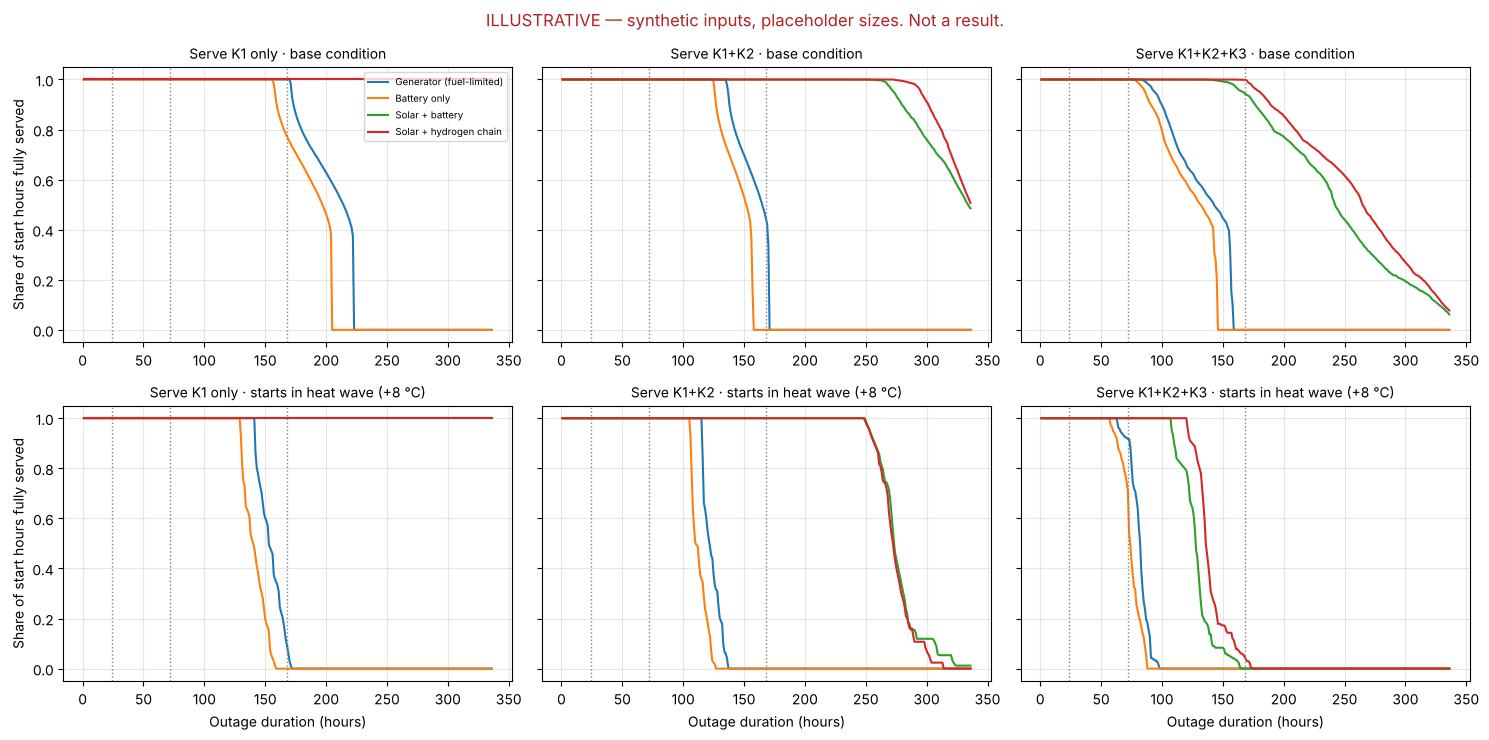

In [6]:
d = np.arange(1, DMAX+1)
# starts inside the heat-wave window (the 7 hottest days of the synthetic year)
seasonal_ = 19 + 10*np.sin(2*np.pi*(day-110)/365)
peak_day = int(np.argmax(seasonal_))//24
in_hw = (day >= peak_day-3) & (day <= peak_day+3)
def surv(aut, mask=None):
    a = aut if mask is None else aut[mask]
    return np.array([(a >= x).mean() for x in d])

fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for r, (res, msk, cond) in enumerate(((base, None, "base condition"), (heat, in_hw, "starts in heat wave (+8 °C)"))):
    for c, lv in enumerate(LEVELS):
        a = ax[r, c]
        for name, aut in res[lv].items():
            a.plot(d, surv(aut, msk), label=name)
        a.set_title(f"Serve {lv} · {cond}", fontsize=10); a.grid(alpha=.3)
        for x in (24, 72, 168): a.axvline(x, color="grey", ls=":", lw=1)
        if r == 1: a.set_xlabel("Outage duration (hours)")
    ax[r, 0].set_ylabel("Share of start hours fully served")
ax[0, 0].legend(loc="upper right", fontsize=7)
fig.suptitle("ILLUSTRATIVE — synthetic inputs, placeholder sizes. Not a result.", color="firebrick")
plt.tight_layout(); plt.show()

## 5 · Decision table when the duration is unknown (regret)
For each target duration, *regret* of an option = (best option's survival share) − (this option's share). The last column shows each option's **worst-case regret** across the listed durations. Again: the numbers come from placeholders and only show how the table is built.

In [7]:
targets = [24, 72, 168]
def regret_table(res, mask=None):
    S = pd.DataFrame({n: [ ((a if mask is None else a[mask]) >= x).mean() for x in targets] for n, a in res.items()}, index=[f"{x} h" for x in targets])
    R = S.rsub(S.max(axis=1), axis=0)
    R.loc["worst-case regret"] = R.max()
    return S.round(2), R.round(2)

for lv in LEVELS:
    for label, res, msk in (("BASE", base, None), ("HEAT WAVE", heat, in_hw)):
        S, R = regret_table(res[lv], msk)
        print(f"=== Serve {lv} · {label}: survival share, then regret (last row = worst case) ===")
        display(pd.concat({"survival": S, "regret": R}, axis=0))

=== Serve K1 only · BASE: survival share, then regret (last row = worst case) ===


Generator (fuel-limited)  Battery only  Solar + battery  Solar + hydrogen chain
survival 24 h                                    1.0          1.00              1.0                     1.0
         72 h                                    1.0          1.00              1.0                     1.0
         168 h                                   1.0          0.77              1.0                     1.0
regret   24 h                                    0.0          0.00              0.0                     0.0
         72 h                                    0.0          0.00              0.0                     0.0
         168 h                                   0.0          0.23              0.0                     0.0
         worst-case regret                       0.0          0.23              0.0                     0.0

=== Serve K1 only · HEAT WAVE: survival share, then regret (last row = worst case) ===


Generator (fuel-limited)  Battery only  Solar + battery  Solar + hydrogen chain
survival 24 h                                   1.00           1.0              1.0                     1.0
         72 h                                   1.00           1.0              1.0                     1.0
         168 h                                  0.09           0.0              1.0                     1.0
regret   24 h                                   0.00           0.0              0.0                     0.0
         72 h                                   0.00           0.0              0.0                     0.0
         168 h                                  0.91           1.0              0.0                     0.0
         worst-case regret                      0.91           1.0              0.0                     0.0

=== Serve K1+K2 · BASE: survival share, then regret (last row = worst case) ===


Generator (fuel-limited)  Battery only  Solar + battery  Solar + hydrogen chain
survival 24 h                                   1.00           1.0              1.0                     1.0
         72 h                                   1.00           1.0              1.0                     1.0
         168 h                                  0.44           0.0              1.0                     1.0
regret   24 h                                   0.00           0.0              0.0                     0.0
         72 h                                   0.00           0.0              0.0                     0.0
         168 h                                  0.56           1.0              0.0                     0.0
         worst-case regret                      0.56           1.0              0.0                     0.0

... (2 outputs left out)

=== Serve K1+K2+K3 · BASE: survival share, then regret (last row = worst case) ===


Generator (fuel-limited)  Battery only  Solar + battery  Solar + hydrogen chain
survival 24 h                                    1.0           1.0             1.00                     1.0
         72 h                                    1.0           1.0             1.00                     1.0
         168 h                                   0.0           0.0             0.94                     1.0
regret   24 h                                    0.0           0.0             0.00                     0.0
         72 h                                    0.0           0.0             0.00                     0.0
         168 h                                   1.0           1.0             0.06                     0.0
         worst-case regret                       1.0           1.0             0.06                     0.0

=== Serve K1+K2+K3 · HEAT WAVE: survival share, then regret (last row = worst case) ===


Generator (fuel-limited)  Battery only  Solar + battery  Solar + hydrogen chain
survival 24 h                                   1.00          1.00             1.00                    1.00
         72 h                                   0.92          0.71             1.00                    1.00
         168 h                                  0.00          0.00             0.00                    0.05
regret   24 h                                   0.00          0.00             0.00                    0.00
         72 h                                   0.08          0.29             0.00                    0.00
         168 h                                  0.05          0.05             0.05                    0.00
         worst-case regret                      0.08          0.29             0.05                    0.00

## 6 · What the next versions replace
| Placeholder here | Replaced by | When |
|---|---|---|
| Synthetic hourly temperature and sun | Adana hourly weather (open data), later the Kashiwa station | W01 to W02 |
| Synthetic tier loads (`TIERS` block) | Campus hourly consumption (requested) via `campus_hourly_load.csv`; otherwise a public typical profile labelled *synthetic*. Tier shares come from the campus site register | Data decision 20 Nov |
| Placeholder sizes | Campus equipment data (generator, solar, storage) where available | After data |
| Equal stored energy, all stores full at outage start | Realistic states of charge | M05 |
| Equal-weight start hours | Same, stated explicitly; no probability claim | — |

*Outside this model by design:* equipment failures, tank pressure and hydrogen availability effects, cost optimisation.